<a href="https://colab.research.google.com/github/qingyueliu/ml4ss-qingyue/blob/main/student_demo/qingyue/%E2%80%9Cweek03_02_unsupervised_explanation_ipynb%E2%80%9D_qingyue.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# STATS 201 Week 3 · 02 Unsupervised Explanation

**Question.** Which requests in a WildChat-derived table use similar language?

**How to work.** In Colab, choose **File → Save a copy in Drive**. Run the cells in order on CPU. Read the saved default outputs if Hugging Face is temporarily unavailable. Run with K = 4 first. Then change K to 3 or 5 and compare a gallery panel.

For Ed, share one figure or panel, a view-access link to your Colab copy, your interpretation and one check. The result displays inline.

## 1 · Define the pattern-finding task

Shen (ICML 2025, Appendix A.2) reused WildChat and LMSYS and clustered sentence embeddings following [Zheng et al.'s K-means procedure](https://arxiv.org/abs/2309.11998). The author then reviewed and interpreted themes. This classroom adaptation uses the author's public WildChat-derived table and **TF–IDF** so it can run on CPU. One row is one user request. TF–IDF gives more weight to words that occur in a request and are less common across requests in the slice.

K-means finds centers $\mu_j$ and assignments $z_i$ for the request vectors $x_i$:

$$ \min_{\mu,z}\sum_{i=1}^{n}\lVert x_i-\mu_{z_i}\rVert_2^2. $$

The fit reads **user_prompt**. The published **cluster_id** is used only in the optional after-fit comparison. For a short lesson we take the first 400 rows returned by the API and apply the documented length and text filter. This is an ordered convenience slice of an already selected corpus. We display aggregate terms rather than raw messages. Interpret a theme as a judgment about this slice and representation.

**Your turn.** Run with K = 4. Try 3 or 5. Which themes split or merge? Cluster numbers can be relabelled across fits. Compare words and sizes.

### Explanation pseudocode and intuition

Think of each request as a point with one coordinate for each word in the vocabulary. TF–IDF gives a request a larger coordinate for words used in that request that are relatively uncommon across the collection. K-means groups nearby points. The center summarizes the average word-weight pattern of its members.

```text
Read 400 rows in source order
Keep requests of 8 to 90 words that pass the text filters and remove duplicates
Remove common English stop words and keep terms seen in at least 3 requests
Drop terms present in more than 80 percent of the retained requests
Convert each request to a normalized TF–IDF vector
Choose K = 4 and set the random seed to 201
FOR each of 12 starting configurations
    Assign each vector to its nearest center by squared Euclidean distance
    Replace each center with the average of its assigned vectors
    Repeat the assignment and update until the solver stops
END FOR
Keep the fit with the smallest total squared distance to the assigned centers
Summarize group sizes and center terms
Project the vectors and centers to two dimensions and draw the gallery
```

For term $t$, scikit-learn uses $\mathrm{idf}(t)=1+\log((1+N)/(1+\mathrm{df}(t)))$ with the default smoothing. $N$ counts retained requests and $\mathrm{df}(t)$ counts requests containing that term. It multiplies the term count by this weight and scales each nonzero request vector to unit Euclidean length. During grouping, K-means reduces the sum of squared distances from requests to their assigned centers. [TF–IDF documentation](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting) · [K-means documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

In [1]:
# Read and run. The data loader makes public Hugging Face requests.

import json
import time
from io import BytesIO
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image as NotebookImage, display

import re
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from threadpoolctl import threadpool_limits

DATA_SERVER = "https://datasets-server.huggingface.co"
WILDCHAT = "heyyjudes/wildchat-creative-only-labeled"

def read_url(url):
    for attempt in range(3):
        try:
            with urlopen(url, timeout=25) as response:
                return response.read()
        except (URLError, TimeoutError) as error:
            if isinstance(error, HTTPError) and error.code not in {429, 500, 502, 503, 504}:
                raise RuntimeError(f"Hugging Face returned HTTP {error.code}. Rerun the data cell.") from error
            if attempt == 2:
                raise RuntimeError("Hugging Face is unavailable. The saved default outputs can support discussion.") from error
            time.sleep(2 ** attempt)

def page(dataset, offset=0, first=False):
    params = {"dataset": dataset, "config": "default", "split": "train"}
    endpoint = "first-rows" if first else "rows"
    if not first:
        params.update(offset=offset, length=100)
    return json.loads(read_url(f"{DATA_SERVER}/{endpoint}?{urlencode(params)}"))["rows"]

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=125, bbox_inches="tight")
    plt.close(fig)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
# Read and run once. This is an ordered teaching slice of the author's public table.
with ThreadPoolExecutor(max_workers=4) as pool:
    prompt_rows = [
        entry["row"]
        for batch in pool.map(lambda offset: page(WILDCHAT, offset), range(0, 400, 100))
        for entry in batch
    ]

contact_or_markup = re.compile(r"https?://|www\.|[\w.+-]+@[\w.-]+\.\w+|(?:\d[\s()-]*){7,}|<[^>]+>|" + chr(96)*3, re.I)
sensitive = re.compile(r"\b(?:explicit|porn\w*|sexual\w*|rape\w*|incest|suicid\w*|gore|nude|naked|erotic|nsfw|sex|tortur\w*|fetish|orgasm|breasts?|genitals?|molest\w*|kill\w*|murder\w*|blood\w*|drugs?|abuse\w*|nazi\w*)\b", re.I)
def keep_prompt(text):
    return (isinstance(text, str) and 8 <= len(text.split()) <= 90
            and not contact_or_markup.search(text) and not sensitive.search(text))

clean_prompts = [row for row in prompt_rows if keep_prompt(row.get("user_prompt"))]
prompt_table = pd.DataFrame(clean_prompts).drop_duplicates("user_prompt").reset_index(drop=True)
assert len(prompt_table) >= 35, "The returned sample is too small for this activity."
print(f"Fetched {len(prompt_rows)} rows; retained {len(prompt_table)} short, distinct requests.")

Fetched 400 rows; retained 222 short, distinct requests.


### Read the sample counts

The saved run fetched **400 rows** from the public derived table and retained **222 requests**, or **55.5%** of the fetched rows, after the filters and deduplication. That denominator is the ordered teaching slice. The resulting vocabulary and cluster counts describe the retained requests. To study a wider community, define who belongs in the population and how the sample represents them.

## 2 · Fit and interpret

**Your turn.** Edit **K** in the cell below. K is the requested number of clusters. The default is 4. When you try 3 or 5, compare the displayed cluster sizes and top terms with your first run. Cluster numbers can change across fits.

scikit-learn builds TF–IDF vectors and fits K-means. The optional cross-tab compares the fitted groups with source groups after fitting.

,Cluster,Rows,Top terms
0,0,55,"write, story, man, tracer, make"
1,1,14,"correct, confidence, answer, rate, scale"
2,2,112,"make, like, using, character, old"
3,3,21,"scene, minute, movie, dialogue, complex"
4,4,20,"create, businesses, review, based, app"


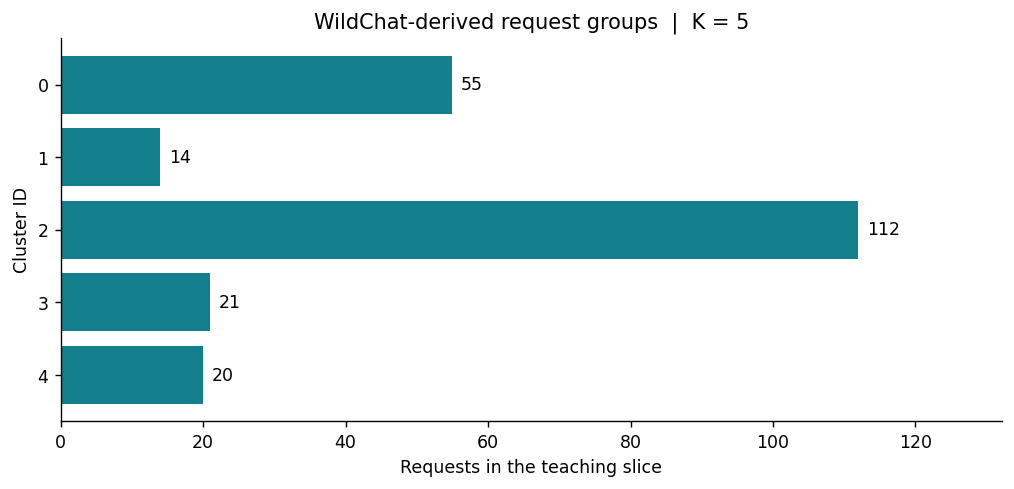

,New cluster,Source cluster,Overlap rows
0,0,30,15
1,1,23,8
2,2,22,10
3,3,43,9
4,4,7,6


In [3]:
# Your turn · change K to 3 or 5 after the default run.
K = 5
assert K in {3, 4, 5}

vectorizer = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.80,
                             token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
X_prompt = vectorizer.fit_transform(prompt_table["user_prompt"])
with threadpool_limits(limits=1):
    km = KMeans(n_clusters=K, n_init=12, random_state=201).fit(X_prompt)
cluster = km.labels_
terms = vectorizer.get_feature_names_out()
top_words = [", ".join(terms[np.argsort(weights)[-5:][::-1]]) for weights in km.cluster_centers_]
clusters = pd.DataFrame({
    "Cluster": np.arange(K),
    "Rows": np.bincount(cluster, minlength=K),
    "Top terms": top_words,
})
display(clusters)

fig, ax = plt.subplots(figsize=(8.0, 3.8), layout="constrained")
bars = ax.barh(clusters["Cluster"].astype(str), clusters["Rows"], color="#137f8c")
ax.bar_label(bars, padding=5)
ax.set_xlim(0, clusters["Rows"].max() * 1.18)
ax.set(xlabel="Requests in the teaching slice", ylabel="Cluster ID", title=f"WildChat-derived request groups  |  K = {K}")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

# Optional check after fitting: overlap with the author's most common source group in each new cluster.
most_common = (
    pd.DataFrame({"New cluster": cluster, "Source cluster": prompt_table["cluster_id"]})
    .value_counts().rename("Overlap rows").reset_index()
    .sort_values(["New cluster", "Overlap rows", "Source cluster"], ascending=[True, False, True])
    .drop_duplicates("New cluster")
)
display(most_common.reset_index(drop=True))

### Read group size, top terms and overlap

| Fitted cluster | Share of the 222 retained requests | Most frequent source group and overlap |
|---:|---:|---|
| 0 | 61.3% | Source group 22, 10 of 136 |
| 1 | 22.5% | Source group 30, 12 of 50 |
| 2 | 9.9% | Source group 43, 8 of 22 |
| 3 | 6.3% | Source group 23, 8 of 14 |

The bars show **counts**, so cluster 0 is the largest group in this slice. Group IDs are labels assigned by the fit. Each top-term list contains the five largest coordinates of that group's center, which are average TF–IDF weights. A possible name for cluster 1 is *story writing*, based on words such as *write*, *story* and *movie*. Inspect more requests before using that name as a research category.

In the overlap table, **10 of 136** means that 10 requests in fitted cluster 0 also belong to its most frequent source group, group 22. Other members may belong to other source groups. The source groups enter this descriptive comparison after fitting. An accuracy calculation would require reference categories with agreed meanings.

## 3 · Explanation gallery

Rerun the fit and this cell after changing K. Compare group terms and sizes across runs. The gallery displays inline and can also be saved as a PNG in the session.

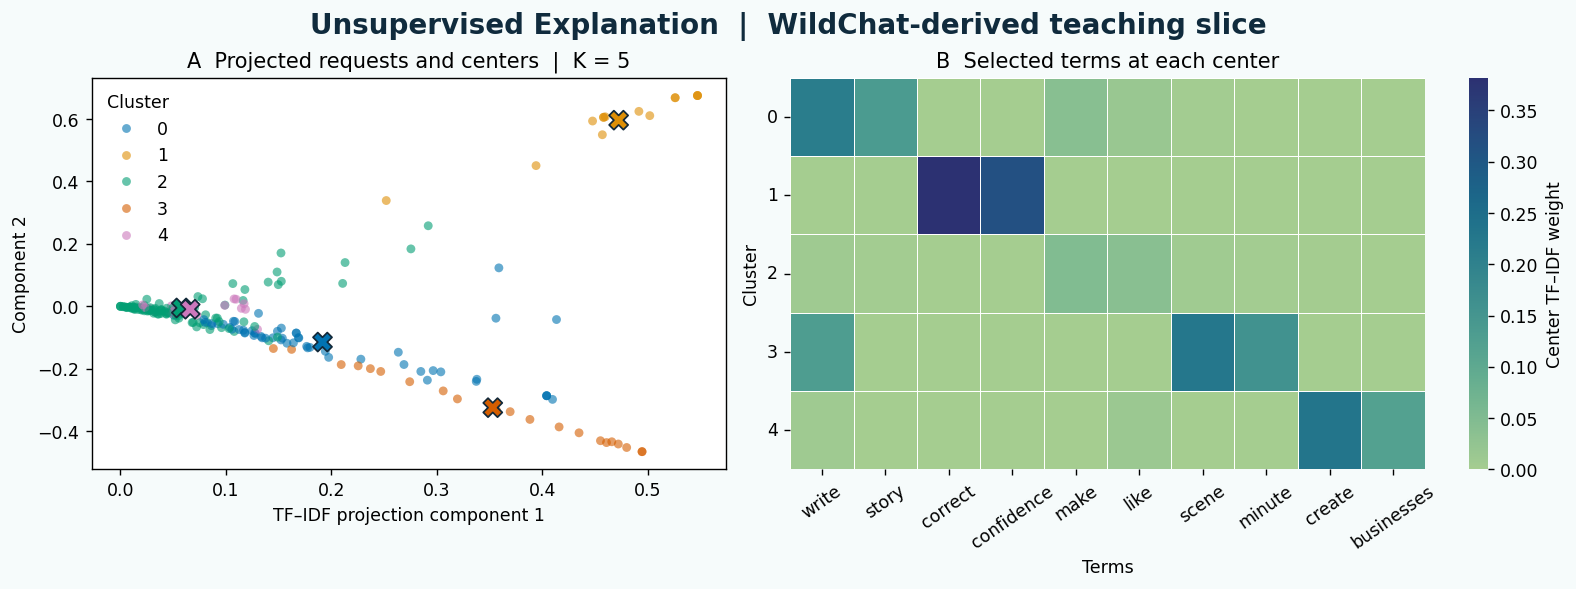

In [4]:
# Read and run after fitting K-means. This cell makes the two-panel gallery.
def explanation_gallery(filename="STATS201_Week3_Explanation_Gallery.png"):
    with threadpool_limits(limits=1):
        svd = TruncatedSVD(n_components=2, random_state=201).fit(X_prompt)
        projected = svd.transform(X_prompt)
        centers = svd.transform(km.cluster_centers_)
    selected = list(dict.fromkeys(
        int(i) for center in km.cluster_centers_ for i in np.argsort(center)[-2:][::-1]
    ))
    weights = pd.DataFrame(km.cluster_centers_[:, selected],
                           columns=terms[selected], index=np.arange(K))
    palette = sns.color_palette("colorblind", K)
    fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.6), layout="constrained", facecolor="#f6fbfb")
    sns.scatterplot(x=projected[:, 0], y=projected[:, 1], hue=cluster.astype(str),
                    hue_order=[str(j) for j in range(K)], palette=palette,
                    ax=a, alpha=.60, s=26, linewidth=0)
    a.scatter(centers[:, 0], centers[:, 1], c=palette, marker="X",
              s=120, edgecolor="#122838", linewidth=1.0)
    a.set(title=f"A  Projected requests and centers  |  K = {K}",
          xlabel="TF–IDF projection component 1", ylabel="Component 2")
    a.legend(title="Cluster", frameon=False)
    sns.heatmap(weights, cmap="crest", ax=b, linewidths=.5,
                cbar_kws={"label": "Center TF–IDF weight"})
    b.set(title="B  Selected terms at each center", xlabel="Terms", ylabel="Cluster")
    b.tick_params(axis="x", labelrotation=35)
    b.tick_params(axis="y", labelrotation=0)
    fig.suptitle("Unsupervised Explanation  |  WildChat-derived teaching slice",
                 fontsize=16, color="#102b3d", fontweight="bold")
    if filename:
        fig.savefig(filename, dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
    show_figure(fig)

explanation_gallery()

### Read both gallery panels

| Panel | What to read |
|---|---|
| A · Projected requests and centers | Each dot is one retained request. The color gives its cluster from the full TF–IDF vectors. The crosses are the fitted centers projected into the same display. The two axes are coordinates derived by Truncated SVD. Nearby points in the display can differ on features that the two coordinates compress. |
| B · Selected terms at each center | Each row is a fitted center and each column is a selected term. The code combines the two leading terms from each center into one shared set of columns. The color scale shows the average TF–IDF weight of that term in the group. A larger weight highlights a candidate term for interpreting the group. |

## Conclusions and assumptions

**What the results support.** At $K=4$, the retained requests form groups with different sizes and word-use profiles. Those profiles suggest themes to investigate. Changing $K$ gives you a way to check whether a proposed theme persists when the partition changes.

**What the interpretation assumes.** Similar word weights need to reflect the kind of similarity your question cares about. This representation emphasizes word use. Word order, context and alternative phrasing may change the meaning that a reader sees. Squared Euclidean distance favors groups that are compact around a mean in the chosen feature space. The sample order, filters, vocabulary and value of $K$ all shape the partition. To generalize a theme, check it against other relevant samples and justify its interpretation. A claim about causes would require a study design that identifies a causal relationship.

## Sources and transfer

Name one theme and one feature or sample change that could challenge it. The displayed aggregates describe this filtered slice and its text representation.

- [Zhao et al. (2024), WildChat source paper](https://arxiv.org/abs/2405.01470) and [source dataset](https://huggingface.co/datasets/allenai/WildChat-1M).
- [Shen (2025), ICML, Appendix A.2](https://proceedings.mlr.press/v267/shen25r.html) and [public WildChat-derived table](https://huggingface.co/datasets/heyyjudes/wildchat-creative-only-labeled). The table has no separate license field at the checked revision. The lab fetches rows in place and shows aggregates.